# qPCR Ct → Fold Change Calculator (ΔΔCt method)

This notebook builds, step by step, a calculator that turns **raw Ct values** from an RT‑qPCR experiment on mRNA
into **fold change in gene expression**, and then plots the result.

## The method: Livak 2^‑ΔΔCt

The standard way to do relative quantification is the **comparative Ct (2^‑ΔΔCt) method**
(Livak & Schmittgen, *Methods* 2001, 25:402–408):

1. **Average technical replicates** → one Ct per gene per sample.
2. **Normalise to reference (housekeeping) gene(s)** — corrects for different amounts of RNA/cDNA loaded:
   ΔCt = Ct(gene of interest) − Ct(reference)
3. **Compare to the control (calibrator) group**:
   ΔΔCt = ΔCt(sample) − mean ΔCt(control group)
4. **Convert to fold change** (each cycle = doubling of product):
   Fold change = 2^(−ΔΔCt)

**When there is more than one reference gene** (recommended — Vandesompele et al., *Genome Biology* 2002;
MIQE guidelines, Bustin et al., *Clin Chem* 2009) we use their **arithmetic mean Ct**, which is the same as the
geometric mean of their expression levels.

**Key assumption:** both the gene of interest and the reference genes amplify with ~100% efficiency
(90–110%, i.e. standard‑curve slope ≈ −3.3). If efficiencies differ a lot, use the Pfaffl method
(Pfaffl, *Nucleic Acids Res* 2001) instead.

**Statistics** are done on ΔCt values (they are roughly normally distributed), *not* on fold changes
(which are skewed, because they are exponential).

## Step 0 — Import the tools we need

In [1]:
import pandas as pd               # tables
import numpy as np                # maths
import matplotlib.pyplot as plt   # plotting
from scipy import stats           # t-test

## Step 1 — Enter the raw Ct values

One row per qPCR well, the same "long" layout most qPCR machines export:

| column | meaning |
|---|---|
| `sample` | biological sample name (e.g. one patient / one tissue sample) |
| `group` | experimental condition |
| `gene` | target gene measured in that well |
| `ct` | raw Ct (Cq) value |

Example experiment: **Control** (normal) tissue vs **Tumour** tissue, 3 biological replicates each, 3 technical replicates per gene.
- Gene of interest: **IL6**
- Reference genes: **GAPDH** and **ACTB**

👉 To use your own data, replace this cell with `raw = pd.read_csv("my_ct_values.csv")` (same four columns).

In [2]:
raw_rows = [
    # sample, group,   gene,    ct
    ("C1", "Control", "GAPDH", 18.10), ("C1", "Control", "GAPDH", 18.21), ("C1", "Control", "GAPDH", 18.05),
    ("C1", "Control", "ACTB",  17.02), ("C1", "Control", "ACTB",  17.10), ("C1", "Control", "ACTB",  16.95),
    ("C1", "Control", "IL6",   28.30), ("C1", "Control", "IL6",   28.45), ("C1", "Control", "IL6",   28.21),

    ("C2", "Control", "GAPDH", 18.40), ("C2", "Control", "GAPDH", 18.35), ("C2", "Control", "GAPDH", 18.52),
    ("C2", "Control", "ACTB",  17.30), ("C2", "Control", "ACTB",  17.41), ("C2", "Control", "ACTB",  17.25),
    ("C2", "Control", "IL6",   28.90), ("C2", "Control", "IL6",   28.75), ("C2", "Control", "IL6",   28.82),

    ("C3", "Control", "GAPDH", 17.95), ("C3", "Control", "GAPDH", 18.02), ("C3", "Control", "GAPDH", 17.90),
    ("C3", "Control", "ACTB",  16.88), ("C3", "Control", "ACTB",  16.80), ("C3", "Control", "ACTB",  16.93),
    ("C3", "Control", "IL6",   27.80), ("C3", "Control", "IL6",   27.95), ("C3", "Control", "IL6",   27.70),

    ("T1", "Tumour", "GAPDH", 18.20), ("T1", "Tumour", "GAPDH", 18.12), ("T1", "Tumour", "GAPDH", 18.30),
    ("T1", "Tumour", "ACTB",  17.15), ("T1", "Tumour", "ACTB",  17.05), ("T1", "Tumour", "ACTB",  17.20),
    ("T1", "Tumour", "IL6",   25.60), ("T1", "Tumour", "IL6",   25.48), ("T1", "Tumour", "IL6",   25.71),

    ("T2", "Tumour", "GAPDH", 18.60), ("T2", "Tumour", "GAPDH", 18.55), ("T2", "Tumour", "GAPDH", 18.71),
    ("T2", "Tumour", "ACTB",  17.50), ("T2", "Tumour", "ACTB",  17.58), ("T2", "Tumour", "ACTB",  17.44),
    ("T2", "Tumour", "IL6",   25.70), ("T2", "Tumour", "IL6",   25.85), ("T2", "Tumour", "IL6",   25.62),

    ("T3", "Tumour", "GAPDH", 18.05), ("T3", "Tumour", "GAPDH", 18.00), ("T3", "Tumour", "GAPDH", 18.15),
    ("T3", "Tumour", "ACTB",  16.95), ("T3", "Tumour", "ACTB",  17.02), ("T3", "Tumour", "ACTB",  16.90),
    ("T3", "Tumour", "IL6",   25.10), ("T3", "Tumour", "IL6",   25.95), ("T3", "Tumour", "IL6",   25.22),
]

raw = pd.DataFrame(raw_rows, columns=["sample", "group", "gene", "ct"])
raw.head(9)

,sample,group,gene,ct
0,C1,Control,GAPDH,18.10
1,C1,Control,GAPDH,18.21
2,C1,Control,GAPDH,18.05
3,C1,Control,ACTB,17.02
4,C1,Control,ACTB,17.10
5,C1,Control,ACTB,16.95
6,C1,Control,IL6,28.30
7,C1,Control,IL6,28.45
8,C1,Control,IL6,28.21


## Step 2 — Tell the calculator which genes and groups are which

In [3]:
gene_of_interest = "IL6"
reference_genes  = ["GAPDH", "ACTB"]
control_group    = "Control"

## Step 3 — Quality control of technical replicates

Technical replicates should agree closely. A common rule of thumb:
- **SD of technical replicates > 0.3 cycles** → check for a pipetting error / outlier well.
- **Ct > 35** → very low expression, unreliable.

We only *flag* problems here; deciding to remove a well is the scientist's call.

In [4]:
qc = raw.groupby(["sample", "gene"])["ct"].agg(["mean", "std", "count"]).reset_index()
qc["flag"] = ""
qc.loc[qc["std"] > 0.3, "flag"] = "high SD - check replicates"
qc.loc[qc["mean"] > 35, "flag"] = "Ct > 35 - low expression"

print("Wells to check:")
print(qc[qc["flag"] != ""] if (qc["flag"] != "").any() else "none")

Wells to check:
   sample gene       mean       std  count                        flag
17     T3  IL6  25.423333  0.460036      3  high SD - check replicates


Sample **T3 / IL6** is flagged: one well (25.95) is ~0.8 cycles off the other two. In a real experiment you might exclude it; here we keep it so the numbers stay transparent.

## Step 4 — Average the technical replicates (one Ct per gene per sample)

In [5]:
mean_ct = raw.groupby(["sample", "group", "gene"])["ct"].mean().reset_index()

# turn it into a wide table: one row per sample, one column per gene
table = mean_ct.pivot(index=["sample", "group"], columns="gene", values="ct").reset_index()
table

gene,sample,group,ACTB,GAPDH,IL6
0,C1,Control,17.023333,18.120000,28.320000
1,C2,Control,17.320000,18.423333,28.823333
2,C3,Control,16.870000,17.956667,27.816667
3,T1,Tumour,17.133333,18.206667,25.596667
4,T2,Tumour,17.506667,18.620000,25.723333
5,T3,Tumour,16.956667,18.066667,25.423333


## Step 5 — Reference Ct for each sample

With two reference genes we take the mean of their Ct values
(= geometric mean of their expression levels, as recommended by Vandesompele et al. 2002).

In [6]:
table["ref_ct"] = table[reference_genes].mean(axis=1)
table[["sample", "group"] + reference_genes + ["ref_ct"]]

gene,sample,group,GAPDH,ACTB,ref_ct
0,C1,Control,18.120000,17.023333,17.571667
1,C2,Control,18.423333,17.320000,17.871667
2,C3,Control,17.956667,16.870000,17.413333
3,T1,Tumour,18.206667,17.133333,17.670000
4,T2,Tumour,18.620000,17.506667,18.063333
5,T3,Tumour,18.066667,16.956667,17.511667


## Step 6 — ΔCt: normalise the gene of interest to the reference

ΔCt = Ct(gene of interest) − Ct(reference)

A **lower** ΔCt means **more** mRNA of the gene of interest (it crossed the threshold earlier).

In [7]:
table["delta_ct"] = table[gene_of_interest] - table["ref_ct"]
table[["sample", "group", gene_of_interest, "ref_ct", "delta_ct"]]

gene,sample,group,IL6,ref_ct,delta_ct
0,C1,Control,28.320000,17.571667,10.748333
1,C2,Control,28.823333,17.871667,10.951667
2,C3,Control,27.816667,17.413333,10.403333
3,T1,Tumour,25.596667,17.670000,7.926667
4,T2,Tumour,25.723333,18.063333,7.660000
5,T3,Tumour,25.423333,17.511667,7.911667


## Step 7 — ΔΔCt: compare every sample to the control group

ΔΔCt = ΔCt(sample) − average ΔCt of the control group

Control samples therefore end up scattered around ΔΔCt = 0.

In [8]:
control_mean_delta_ct = table.loc[table["group"] == control_group, "delta_ct"].mean()
print(f"Average ΔCt of the {control_group} group = {control_mean_delta_ct:.3f}")

table["delta_delta_ct"] = table["delta_ct"] - control_mean_delta_ct
table[["sample", "group", "delta_ct", "delta_delta_ct"]]

Average ΔCt of the Control group = 10.701


gene,sample,group,delta_ct,delta_delta_ct
0,C1,Control,10.748333,0.047222
1,C2,Control,10.951667,0.250556
2,C3,Control,10.403333,-0.297778
3,T1,Tumour,7.926667,-2.774444
4,T2,Tumour,7.660000,-3.041111
5,T3,Tumour,7.911667,-2.789444


## Step 8 — Fold change = 2^(−ΔΔCt)

Each PCR cycle doubles the product, so a difference of 1 cycle = 2‑fold difference.
- Fold change **> 1** → gene is **up‑regulated** vs control
- Fold change **< 1** → gene is **down‑regulated** vs control

In [9]:
table["fold_change"] = 2 ** (-table["delta_delta_ct"])
table[["sample", "group", "delta_delta_ct", "fold_change"]].round(3)

gene,sample,group,delta_delta_ct,fold_change
0,C1,Control,0.047,0.968
1,C2,Control,0.251,0.841
2,C3,Control,-0.298,1.229
3,T1,Tumour,-2.774,6.842
4,T2,Tumour,-3.041,8.231
5,T3,Tumour,-2.789,6.914


## Step 9 — Summarise each group and test for significance

- The group fold change is calculated from the **mean ΔΔCt** (averaging in log space, as in Livak & Schmittgen 2001).
- The error range is 2^−(mean ΔΔCt ± SD), so error bars are asymmetric — that's expected.
- The **t‑test is run on ΔCt values**, not on fold changes.

In [10]:
summary = table.groupby("group")["delta_delta_ct"].agg(["mean", "std", "count"]).reset_index()
summary["fold_change"] = 2 ** (-summary["mean"])
summary["fc_low"]      = 2 ** (-(summary["mean"] + summary["std"]))
summary["fc_high"]     = 2 ** (-(summary["mean"] - summary["std"]))

control_dct = table.loc[table["group"] == control_group, "delta_ct"]
p_values = {}
for group in summary["group"]:
    if group != control_group:
        group_dct = table.loc[table["group"] == group, "delta_ct"]
        p_values[group] = stats.ttest_ind(group_dct, control_dct).pvalue  # Student's t-test, unpaired

for _, row in summary.iterrows():
    line = f"{gene_of_interest} in {row['group']}: fold change = {row['fold_change']:.2f}  (range {row['fc_low']:.2f}-{row['fc_high']:.2f}, n={row['count']})"
    if row["group"] in p_values:
        line += f"   p = {p_values[row['group']]:.4f}"
    print(line)

IL6 in Control: fold change = 1.00  (range 0.83-1.21, n=3)
IL6 in Tumour: fold change = 7.30  (range 6.58-8.10, n=3)   p = 0.0001


## Step 10 — Visualise

A **bar chart of mean fold change with each biological replicate shown as a dot** is the standard figure for
ΔΔCt data: the bar gives the group result, the dots show the spread, and the dashed line at 1 marks "no change".

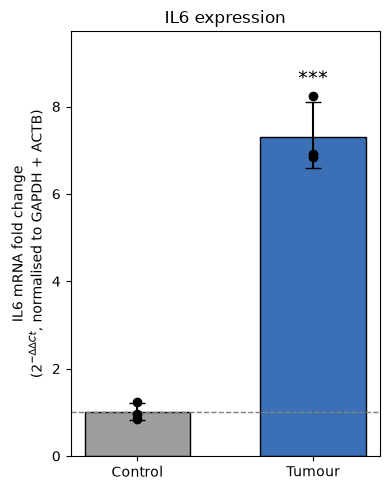

In [11]:
groups = list(summary["group"])
x = np.arange(len(groups))
lower_err = summary["fold_change"] - summary["fc_low"]
upper_err = summary["fc_high"] - summary["fold_change"]

fig, ax = plt.subplots(figsize=(4, 5))
ax.bar(x, summary["fold_change"], yerr=[lower_err, upper_err], capsize=6,
       color=["#9e9e9e", "#3b6fb6"][:len(groups)], edgecolor="black", width=0.6)

# individual biological replicates
for i, group in enumerate(groups):
    points = table.loc[table["group"] == group, "fold_change"]
    ax.scatter(np.full(len(points), x[i]), points, color="black", zorder=3)

ax.axhline(1, linestyle="--", color="grey", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.set_ylabel(f"{gene_of_interest} mRNA fold change\n(2$^{{-ΔΔCt}}$, normalised to {' + '.join(reference_genes)})")
ax.set_title(f"{gene_of_interest} expression")

# significance label above the tumour bar(s)
for i, group in enumerate(groups):
    if group in p_values:
        p = p_values[group]
        stars = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
        ax.text(x[i], summary["fc_high"].iloc[i] * 1.05, stars, ha="center", fontsize=14)

ax.set_ylim(0, summary["fc_high"].max() * 1.2)
plt.tight_layout()
plt.show()

## Step 11 — The whole calculator in one function

Everything above, packed into one reusable function. Give it a raw Ct table and it returns the per‑sample table.

In [12]:
def ct_to_fold_change(raw, gene_of_interest, reference_genes, control_group):
    mean_ct = raw.groupby(["sample", "group", "gene"])["ct"].mean().reset_index()
    t = mean_ct.pivot(index=["sample", "group"], columns="gene", values="ct").reset_index()
    t["ref_ct"] = t[reference_genes].mean(axis=1)
    t["delta_ct"] = t[gene_of_interest] - t["ref_ct"]
    t["delta_delta_ct"] = t["delta_ct"] - t.loc[t["group"] == control_group, "delta_ct"].mean()
    t["fold_change"] = 2 ** (-t["delta_delta_ct"])
    return t

result = ct_to_fold_change(raw, "IL6", ["GAPDH", "ACTB"], "Control")
result[["sample", "group", "delta_ct", "delta_delta_ct", "fold_change"]].round(3)

gene,sample,group,delta_ct,delta_delta_ct,fold_change
0,C1,Control,10.748,0.047,0.968
1,C2,Control,10.952,0.251,0.841
2,C3,Control,10.403,-0.298,1.229
3,T1,Tumour,7.927,-2.774,6.842
4,T2,Tumour,7.660,-3.041,8.231
5,T3,Tumour,7.912,-2.789,6.914


## Step 12 — Self‑check with numbers we can do by hand

Control: GOI 25, reference 20 → ΔCt = 5.  Tumour: GOI 23, reference 20 → ΔCt = 3.
ΔΔCt = 3 − 5 = −2  → fold change = 2² = **4** (tumour has 4× more mRNA).

In [13]:
check = pd.DataFrame([
    ("A", "Control", "GOI", 25.0), ("A", "Control", "REF", 20.0),
    ("B", "Tumour", "GOI", 23.0), ("B", "Tumour", "REF", 20.0),
], columns=["sample", "group", "gene", "ct"])

out = ct_to_fold_change(check, "GOI", ["REF"], "Control").set_index("sample")
assert out.loc["A", "fold_change"] == 1.0
assert out.loc["B", "fold_change"] == 4.0
print("Self-check passed: control = 1.0, tumour = 4.0")

Self-check passed: control = 1.0, tumour = 4.0


## References
- Livak KJ, Schmittgen TD. Analysis of relative gene expression data using real‑time quantitative PCR and the 2^−ΔΔCT method. *Methods* 2001;25:402–408.
- Schmittgen TD, Livak KJ. Analyzing real‑time PCR data by the comparative CT method. *Nature Protocols* 2008;3:1101–1108.
- Pfaffl MW. A new mathematical model for relative quantification in real‑time RT‑PCR. *Nucleic Acids Res* 2001;29:e45.
- Vandesompele J, et al. Accurate normalization of real‑time quantitative RT‑PCR data by geometric averaging of multiple internal control genes. *Genome Biol* 2002;3:research0034.
- Bustin SA, et al. The MIQE guidelines. *Clin Chem* 2009;55:611–622.